# 第01章 误差的代价

> G22 · 本章角色 A2组 · AI辅助初稿。依据仓库四节模板编写，配套实验已由助手执行；学生人工推导、原文核对及B/C独立验证尚未完成，不应将本稿表述为已经验收的教材。

![三格漫画：两个很接近的大数相减，计算器显示0，机器人尝试等价改写。](图片/A-章节导入.svg)

*图01-1 差额去哪儿了？沿用仓库模板概念图，图示不是实验数据。*

## 先看一幕：差额去哪儿了？

机器人想计算两个数的差：当 $x=10^{16}$ 时，$\sqrt{x+1}-\sqrt{x}$ 究竟有多大？它输入公式，屏幕却显示0。同伴把公式改成 $1/(\sqrt{x+1}+\sqrt{x})$，屏幕上出现了约 $5\times10^{-9}$。两个在纸面上完全相等的表达式，为什么给出不同答案？

运行前预测是：直接式会受输入舍入和相近数相减影响，有理化式更可靠。本章将用推导与高精度参考检验这个判断。这里的“差额丢失”不能泛指所有减法；我们还要分清误差在哪一步产生、被哪一步放大。

**本章核心问题：** 当计算机显示3.141592653589793时，我们凭什么相信它？本章围绕浮点数、条件数和稳定性建立判断依据。先修知识为实数运算、导数及Taylor展开。四节各2学时，共8学时。

| 小节 | 学习目标 | 实验 |
| --- | --- | --- |
| 1.1 浮点数与舍入误差 | 理解表示精度，正确报告误差 | 两种精度、小数与求和顺序 |
| 1.2 截断误差与灾难性抵消 | 推导误差项，选择表达式与步长 | 有理化、前向差分扫描 |
| 1.3 条件数与稳定性 | 区分问题敏感性和算法行为 | 标量扰动、同输入的算法比较 |
| 1.4 AI关联：训练中的数值问题 | 解释指数溢出与稳定损失计算 | softmax、交叉熵、微小更新 |

正文与[配套实验Notebook](A2组-实验.ipynb)逐节对应。文中的“实测”均指助手在记录环境中执行的输出，完整表格和图在Notebook及随附CSV中。所有例子均为确定性教学构造，无真实训练集、测试集或物理单位。


**运行方式：** 在本文件所在目录重启内核并运行全部单元。代码会生成当前目录的CSV、环境JSON和图片。本次已用课程指定的NumPy 1.26.4、Matplotlib 3.9.2、pandas 2.2.3运行；实际版本由下方输出及环境JSON记录。主机不支持Jupyter内核通信，本次采用全新Python进程顺序执行；学生仍需在本机JupyterLab重启内核并运行全部。

## 实验操作与验收

本Notebook覆盖1.1—1.4全部实验。每节先看理论与预测，再运行代码，最后对照输出解释。所有数据均为教学构造，不需要下载数据集、不训练神经网络、不需要GPU。

1. 将整个工作目录放入课程仓库；从此Notebook所在目录打开JupyterLab。
2. 选 **Kernel → Restart Kernel and Run All Cells**。不要跳过前面的导入与函数定义单元。
3. 等所有代码单元执行完成，检查末尾汇总及每节输出，再保存。CSV、环境JSON和图片会写到当前工作目录，重新运行会更新这些生成文件。
4. 只打开Notebook即可查看已保存输出。HTML阅读版便于查看，但修改代码应使用 `.ipynb`。

| 小节 | 主要对照 | 验收依据 |
| --- | --- | --- |
| 1.1 | 两种精度、两种求和顺序 | Fraction精确值、理论机器间隔、零值误差尺度 |
| 1.2 | 直接式/有理化、16种差分步长 | 80位与120位Decimal参考、解析导数、完整误差曲线 |
| 1.3 | 三种输入扰动、同一函数的两种算法 | 有限扰动闭式放大率、局部条件数、独立高精度原式 |
| 1.4 | 直接/稳定softmax、概率域/对数域损失 | Decimal参考、有限性与归一化、平移不变性、梯度差分 |

断言只核验本例的具体预期，不将“无报错”当作所有数学结论正确的证明。故意产生inf/NaN的直接计算是受控反例，其失败输出应保留。学生人工核验和B/C独立复核状态见编写报告。


In [1]:
import sys, platform, json, math
from pathlib import Path
from decimal import Decimal, localcontext
from fractions import Fraction
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
out = Path('.')
(out / '图片').mkdir(exist_ok=True)
versions = {'Python': sys.version, 'NumPy': np.__version__, 'pandas': pd.__version__,
            'Matplotlib': matplotlib.__version__, 'platform': platform.platform(),
            'execution_date': '2026-10-19', 'randomness': 'none; deterministic inputs',
            'device': 'CPU', 'course_environment_match': (np.__version__ == '1.26.4' and matplotlib.__version__ == '3.9.2' and pd.__version__ == '2.2.3')}
print(json.dumps(versions, ensure_ascii=False, indent=2))
(out / 'A2组-运行环境.json').write_text(json.dumps(versions, ensure_ascii=False, indent=2), encoding='utf-8')
def dfraction(v):
    f = Fraction.from_float(float(v))
    return Decimal(f.numerator) / Decimal(f.denominator)
def gref(x):
    with localcontext() as c:
        c.prec = 80
        d = Decimal(str(x))
        return (d + 1).sqrt() - d.sqrt()
def stable_difference(x):
    if not math.isfinite(x) or x < 0:
        raise ValueError('x must be finite and nonnegative')
    return 1.0 / (math.sqrt(x + 1.0) + math.sqrt(x))

print("课程核心科学计算依赖匹配：", versions["course_environment_match"])


{
  "Python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "NumPy": "1.26.4",
  "pandas": "2.2.3",
  "Matplotlib": "3.9.2",
  "platform": "Linux-6.18.55-x86_64-with-glibc2.39",
  "execution_date": "2026-10-19",
  "randomness": "none; deterministic inputs",
  "device": "CPU",
  "course_environment_match": true
}
课程核心科学计算依赖匹配： True


## 1.1 浮点数与舍入误差（2学时）

### 概念讲解：机器数怎样表示实数

实数有无限多个，而固定长度的存储只有有限种状态。计算机必须把大多数实数映射到附近的可表示数。二进制正规浮点数可写成

$$(-1)^s(1.b_1b_2\cdots b_{p-1})_2\,2^e.$$

符号位 $s$ 决定正负，指数 $e$ 决定尺度，尾数的有效位数 $p$ 决定同一尺度上的分辨率。IEEE 754的binary32通常对应NumPy的float32：1位符号、8位指数、23位显式小数，含隐藏首位共24位有效二进制位；binary64通常对应float64：1、11、52位，含首位共53位。它们约有7位和16位十进制有效精度，并不意味着每个数都保证相同的十进制有效位数。

有限二进制小数对应分母为2的幂的有理数。十进制 $0.1=1/10$ 的分母含因子5，因而二进制展开无限循环：

$$0.1_{10}=0.0001100110011\cdots_2.$$

以Python的binary64为例，存储值精确等于 $3602879701896397/36028797018963968$，略大于 $1/10$。屏幕打印“0.1”只是简短显示，不代表内部值恰好为 $1/10$。[1]

若真值为 $y$、近似值为 $\widehat y$，定义绝对误差 $E_a=|\widehat y-y|$；当 $y\ne0$ 时，相对误差 $E_r=E_a/|y|$。绝对误差与量同单位，相对误差无量纲。真值为零时不能除以零；应报告绝对误差，或明确说明所选的外部尺度。

### 关键推导：舍入模型的条件

手算一个精确可表示的例子：$0.15625=1/8+1/32=0.00101_2=1.01_2\times2^{-3}$。再考虑仅保留4位有效二进制位的教学格式：$0.1=1.1001100\cdots_2\times2^{-4}$。相邻候选数为 $1.100_2\times2^{-4}=0.09375$ 和 $1.101_2\times2^{-4}=0.1015625$；后者更近，故舍入为0.1015625。绝对误差为0.0015625，相对误差为0.015625。

对有效位数为 $p$ 的二进制格式，1处向上的间隔为 $\varepsilon=2^{1-p}$；采用舍入到最近值时，单位舍入误差为 $u=\varepsilon/2=2^{-p}$。因此float32的 $\varepsilon=2^{-23}$、$u=2^{-24}$，float64的 $\varepsilon=2^{-52}$、$u=2^{-53}$。文献中“机器精度”有时指前者、有时指后者，本章始终区分二者。

在精确结果处于正规数范围、采用最近舍入且无上溢或下溢影响时，单次舍入满足

$$\operatorname{fl}(z)=z(1+\delta),\qquad |\delta|\le u.$$

对基本四则运算，可把 $z$ 理解为浮点输入进行精确运算后的结果。该模型不意味着整个程序的相对误差小于 $u$，也不能不加说明地套用于库函数。正规数区间 $[2^e,2^{e+1})$ 的间隔为 $2^{e-p+1}$，半间隔除以 $|z|\ge2^e$ 即给出上面的界。非正规数在零附近使用固定绝对间隔，统一的相对误差界可能失效；上溢可能产生inf，非法运算可能产生NaN。零与非正规数不能直接套用正规表示式。[2]

### 实验设计：预测、输入与判据

比较float32和float64的 $0.1+0.2$、1处相邻数及两种求和次序。预测两种精度都存在十进制表示误差；较高精度减小误差，但不能保证有限精度满足结合律。

| 项目 | 设计 |
| --- | --- |
| 输入与参数 | 显式dtype的0.1、0.2；顺序求和 $[10^{16},1,-10^{16}]$ 与 $[10^{16},-10^{16},1]$ |
| 独立参考 | Fraction精确分数 $3/10$ 与整数1；参考数在误差计算前不转成浮点 |
| 指标 | 绝对、相对误差；1处向上间隔；真值0时仅绝对误差 |
| 判据 | 间隔必须等于理论值；求和是有意失败的演示，不要求都接近1 |
| 环境 | Python/NumPy/Matplotlib版本见Notebook首单元；CPU，确定性输入，不使用随机数，通常数秒 |



In [2]:
rows=[]
for dt in (np.float32, np.float64):
    y=dt(dt('0.1')+dt('0.2'))
    err=abs(Fraction.from_float(float(y))-Fraction(3,10))
    gap=float(np.nextafter(dt(1),dt(2))-dt(1))
    assert gap == float(np.finfo(dt).eps)
    rows.append(dict(dtype=dt.__name__, input='0.1+0.2', value=float(y), reference='3/10',
                     abs_error=float(err), rel_error=float(err/Fraction(3,10)), gap_at_one=gap))
    for vals in ([1e16,1,-1e16],[1e16,-1e16,1]):
        acc=dt(0)
        for v in vals: acc=dt(acc+dt(v))
        rows.append(dict(dtype=dt.__name__,input=str(vals),value=float(acc),reference='1',
                         abs_error=abs(float(acc)-1), rel_error=abs(float(acc)-1),gap_at_one=gap))
t1=pd.DataFrame(rows)
print(t1.to_string(index=False, float_format=lambda x: format(x,'.17g')))
t1.to_csv('A2组-浮点误差.csv',index=False)
print('float64 gap at 1e16:', np.spacing(np.float64(1e16)))
print('0.1 stored fraction:', Fraction.from_float(0.1))
assert np.float32(0.15625) == 0.15625

# 真值是0时只报告绝对误差；使用精确可表示数避免混入输入舍入。
zero_result = np.float64(0.5) - np.float64(0.5)
assert zero_result == 0
print('真值0：绝对误差=', abs(float(zero_result)), '；相对误差不定义。')
assert float(t1[(t1.dtype=='float64') & (t1.input=='0.1+0.2')].abs_error.iloc[0]) > 0


  dtype              input               value reference              abs_error              rel_error             gap_at_one
float32            0.1+0.2 0.30000001192092896      3/10 1.1920928955078126e-08 3.9736429850260414e-08 1.1920928955078125e-07
float32 [1e+16, 1, -1e+16]                   0         1                      1                      1 1.1920928955078125e-07
float32 [1e+16, -1e+16, 1]                   1         1                      0                      0 1.1920928955078125e-07
float64            0.1+0.2 0.30000000000000004      3/10 4.4408920985006264e-17 1.4802973661668753e-16 2.2204460492503131e-16
float64 [1e+16, 1, -1e+16]                   0         1                      1                      1 2.2204460492503131e-16
float64 [1e+16, -1e+16, 1]                   1         1                      0                      0 2.2204460492503131e-16
float64 gap at 1e16: 2.0
0.1 stored fraction: 3602879701896397/36028797018963968
真值0：绝对误差= 0.0 ；相对误差不定义。


### 补充实验：精度、范围与显示

先预测：float32与float64的最小正规数、最小正非正规数和最大有限数是否相同？“精度”和“范围”分别由哪些位数控制？下表直接读取当前dtype的属性，并对1处间隔与有效位数的关系作检查。

In [3]:
range_rows=[]
for dt in (np.float32,np.float64):
    info=np.finfo(dt)
    range_rows.append(dict(dtype=dt.__name__,significand_bits=info.nmant+1,
        eps=float(info.eps),unit_roundoff=float(info.eps/2),
        min_normal=float(info.tiny),min_positive_subnormal=float(np.nextafter(dt(0),dt(1))),
        max_finite=float(info.max),log_max_finite=float(np.log(info.max))))
    assert info.eps == 2.0**(-info.nmant)
range_table=pd.DataFrame(range_rows)
print(range_table.to_string(index=False))
range_table.to_csv('A2组-精度与范围.csv',index=False)
print('观察：范围和精度是不同属性；非正规数附近相对误差模型须另行判断。')


  dtype  significand_bits          eps  unit_roundoff    min_normal  min_positive_subnormal    max_finite  log_max_finite
float32                24 1.192093e-07   5.960464e-08  1.175494e-38            1.401298e-45  3.402823e+38       88.722839
float64                53 2.220446e-16   1.110223e-16 2.225074e-308           4.940656e-324 1.797693e+308      709.782713
观察：范围和精度是不同属性；非正规数附近相对误差模型须另行判断。


### 结果解释与本节结论

实测结果如下。虽然float32的简短显示可能是“0.3”，其真实误差仍应依据内部二进制值计算。

| dtype | 转成Python float后显示的和 | 相对精确 $3/10$ 的绝对误差 | 相对误差 | 1处向上间隔 |
| --- | --- | --- | --- | --- |
| float32 | 0.30000001192092896 | $1.1920928955\times10^{-8}$ | $3.9736429850\times10^{-8}$ | $1.1920928955\times10^{-7}$ |
| float64 | 0.30000000000000004 | $4.4408920985\times10^{-17}$ | $1.4802973662\times10^{-16}$ | $2.2204460493\times10^{-16}$ |

两种dtype对第一种顺序均得到0，对第二种顺序均得到1。前者先把1加到远大的数上，增量在舍入中丢失；后者先消掉两个相反的大数，再保留1。相对精确目标1，误差分别为1和0。实验使用手写逐次加法控制运算顺序，不把NumPy可能采用的归约策略混入比较。

### 易错点与讨论

多打印几位只能揭示已存储的数，不能增加其准确度。机器间隔还随指数变化，$10^{16}$ 附近float64向上间隔为2，所以“小于 $10^{-15}$ 的误差才算好”不是适用于所有尺度的规则。float64的 $u$ 很小，上面的求和仍可能有100%的相对误差。

**随堂提问：** $0.15625$ 在float32与float64中是否精确？若先手算二进制展开，答案是肯定的：它只有3个有效二进制位且指数在范围内。不能从 $0.1$ 的失败推出“所有十进制小数都不能精确表示”。


## 1.2 截断误差与灾难性抵消（2学时）

### 概念讲解：两种不同来源的误差

即使用精确算术，把导数替换为有限差分也会产生误差，这是截断误差；把中间结果存成浮点数产生的是舍入误差。两者不能混为一谈。相近数相减时，结果比参与运算的数小得多，输入中已有的小误差可能相对于差值被显著放大，这就是灾难性抵消的典型机制。

设两个数约为 $a,b$，各自已有绝对误差 $e_a,e_b$，则相减后的误差为 $e_a-e_b$，其相对大小为 $|e_a-e_b|/|a-b|$。当分母很小时，相对误差可能很大。这并不要求减法本身再次引入巨大舍入；某些相近浮点数相减甚至可以精确，主要信息已在之前的计算中丢失。

### 关键推导：差分误差与有理化

若 $f\in C^2$ 且区间包含 $x$ 和 $x+h$，Taylor公式给出某个中间点 $\xi$，使

$$f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(\xi).$$

定义前向差分 $D_hf(x)=[f(x+h)-f(x)]/h$，则

$$D_hf(x)-f'(x)=\frac h2 f''(\xi),\qquad |D_hf(x)-f'(x)|\le\frac{M_2|h|}{2},$$

其中 $M_2$ 是相应区间内 $|f''|$ 的上界。这里的 $O(h)$ 结论描述精确算术下的离散近似。若两个函数值各有量级约 $u|f(x)|$ 的误差，除以 $h$ 后，舍入贡献常具有 $B u/|h|$ 的量级，于是得到教学估计

$$E(h)\ \lesssim\ A|h|+\frac{Bu}{|h|}.$$

在 $A,B>0$ 且近似模型适用时，令右侧对正 $h$ 求导，得到平衡尺度 $h_{\rm bal}\approx\sqrt{Bu/A}$。这不是保证最优步长的定理：常数、函数值计算、输入 $x+h$ 的舍入及偶然抵消都会改变实际最小值。若 $x+h$ 被舍入为 $x$，实际取样点已重合。

对于开场的 $g(x)=\sqrt{x+1}-\sqrt{x}$，在实数 $x\ge0$ 时分母为正，因此

$$g(x)=\frac{(\sqrt{x+1}-\sqrt{x})(\sqrt{x+1}+\sqrt{x})}{\sqrt{x+1}+\sqrt{x}}
=\frac1{\sqrt{x+1}+\sqrt{x}}.$$

新式避免了两个近似平方根相减。特别地，在 $x=10^{16}$ 的float64计算中，$x+1$ 首先就被舍入回 $x$，所以直接式得到0。新式把精确差的分子1显式保留下来；分母中的 $x+1$ 仍可能被舍入，但对大而平稳的分母影响很小。

### 实验设计：预测、输入与判据

| 项目 | 设计 |
| --- | --- |
| 输入 | 起步例 $x=10^{16}$；另取 $f(x)=e^x,x=1,h=10^{-k},k=1,\ldots,16$ |
| 预测 | 有理化式接近参考，直接式为0；差分误差总体先下降后回升 |
| 独立参考 | 80位Decimal计算平方根差；Decimal.exp计算 $e$ 和精确十进制步长下的差分 |
| 指标与判据 | 平方根差相对误差，有理化要求 $<10^{-14}$；差分绝对误差，完整保存所有步长 |
| 环境与预算 | 同1.1；CPU、无随机数，无量纲，约数秒 |



In [4]:
x=1e16
naive=math.sqrt(x+1)-math.sqrt(x)
stable=stable_difference(x)
ref=gref(x)
with localcontext() as c:
    c.prec=80
    e_stable=abs(dfraction(stable)-ref)/abs(ref)
print('x+1 == x:',x+1==x)
print('naive:',naive,'stable:',stable,'reference:',ref,'stable relative error:',e_stable)
assert naive == 0
assert e_stable < Decimal('1e-14')
assert stable_difference(0) == 1


x+1 == x: True
naive: 0.0 stable: 5e-09 reference: 4.99999999999999987500000000000000624999999999999960937500000000E-9 stable relative error: 4.5922560830128472573390654842499671161196757352099962491665234464829906940593742E-17


           h  approximation   truncation  implementation  total_error  actual_increment
1.000000e-01       2.858842 1.405601e-01    4.273041e-15 1.405601e-01      1.000000e-01
1.000000e-02       2.731919 1.363683e-02    1.412664e-15 1.363683e-02      1.000000e-02
1.000000e-03       2.719641 1.359594e-03    3.050724e-13 1.359594e-03      1.000000e-03
1.000000e-04       2.718418 1.359186e-04    1.872886e-12 1.359186e-04      1.000000e-04
1.000000e-05       2.718295 1.359145e-05    4.322497e-11 1.359150e-05      1.000000e-05
1.000000e-06       2.718283 1.359141e-06    1.697979e-10 1.358972e-06      1.000000e-06
1.000000e-07       2.718282 1.359141e-07    4.032592e-09 1.399467e-07      1.000000e-07
1.000000e-08       2.718282 1.359141e-08    2.019416e-08 6.602751e-09      1.000000e-08
1.000000e-09       2.718282 1.359141e-09    2.140827e-07 2.154419e-07      1.000000e-09
1.000000e-10       2.718283 1.359141e-10    1.547574e-06 1.547709e-06      1.000000e-10
1.000000e-11       2.718314 1.35

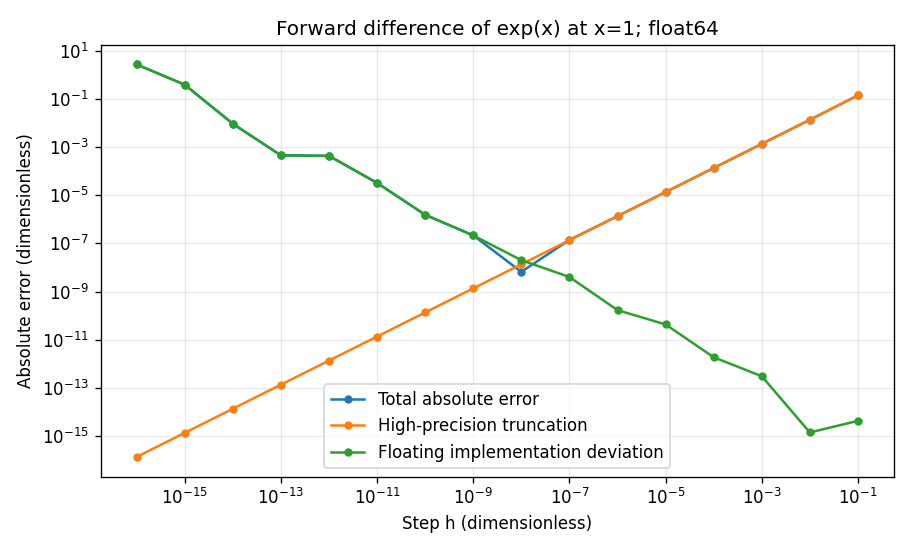

In [5]:
rows=[]
for k in range(1,17):
    hs='1e-'+str(k)
    h=float(hs)
    approx=(math.exp(1+h)-math.exp(1))/h
    with localcontext() as c:
        c.prec=80
        hd=Decimal(hs)
        exact_derivative=Decimal(1).exp()
        exact_difference=((Decimal(1)+hd).exp()-exact_derivative)/hd
        trunc=abs(exact_difference-exact_derivative)
        impl=abs(dfraction(approx)-exact_difference)
        total=abs(dfraction(approx)-exact_derivative)
    rows.append(dict(h=h, approximation=approx, truncation=float(trunc),
                     implementation=float(impl), total_error=float(total),
                     actual_increment=(1+h)-1))
t2=pd.DataFrame(rows)
print(t2.to_string(index=False))
print('smallest observed error:',t2.loc[t2.total_error.idxmin()].to_dict())
t2.to_csv('A2组-差分步长.csv',index=False)
fig,ax=plt.subplots(figsize=(7.6,4.6))
for col,label in [('total_error','Total absolute error'),('truncation','High-precision truncation'),('implementation','Floating implementation deviation')]:
    ax.loglog(t2.h,t2[col],'o-',label=label,markersize=4)
ax.set(xlabel='Step h (dimensionless)',ylabel='Absolute error (dimensionless)',title='Forward difference of exp(x) at x=1; float64')
ax.grid(True,which='both',alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig('图片/A2组-差分误差.png',dpi=180)
plt.show()
assert t2.iloc[-1].approximation == 0


### 参考精度复查与边界输入

高精度输出也需要检查。将参考工作精度由80位提高到120位，比较平方根差参考的相对变化与差分参考导数的相对变化。此检查为本例提供额外证据，不等于形式化证明全部参考位均正确。另检查有限非负输入条件，负数、NaN、inf应明确拒绝。

In [6]:
with localcontext() as c:
    c.prec=120
    xd=Decimal('1e16')
    ref120=(xd+1).sqrt()-xd.sqrt()
    ref80=gref(1e16)
    reference_change=abs(ref80-ref120)/abs(ref120)
    e120=Decimal(1).exp()
    c.prec=80
    e80=Decimal(1).exp()
    c.prec=120
    derivative_reference_change=abs(e80-e120)/abs(e120)
assert reference_change < Decimal('1e-50')
assert derivative_reference_change < Decimal('1e-75')
print('80→120位：平方根差参考相对变化=',reference_change)
print('80→120位：解析导数参考相对变化=',derivative_reference_change)
for bad in [-1., float('nan'), float('inf')]:
    try:
        stable_difference(bad)
    except ValueError:
        print('已按定义域拒绝输入：',bad)
    else:
        raise AssertionError('非法输入未被拒绝')


80→120位：平方根差参考相对变化= 5.46874999999999972656250000000001855472500000000123291109374999995635983984375000255584833984374982490511718749999869824E-66
80→120位：解析导数参考相对变化= 1.99707689049749441261449665827071409867210252747574485211444053005369997983802290209154778554135259231348046317173252661E-81
已按定义域拒绝输入： -1.0
已按定义域拒绝输入： nan
已按定义域拒绝输入： inf


### 结果解释与本节结论

平方根直接式为0，相对参考误差为1；有理化式为 $5\times10^{-9}$，相对误差约为 $4.59\times10^{-17}$。80位Decimal计算的差约为 $4.999999999999999875\times10^{-9}$。这里先在Decimal中比较误差，再转成显示值，避免参考值转float后掩盖细小误差。

![前向差分误差随步长变化](图片/A2组-差分误差.png)

*图01-2 $e^x$ 在 $x=1$ 的前向差分，float64；双对数坐标，无量纲。高精度截断误差和浮点实现偏差分别相对同一个精确十进制步长定义。*

图中“截断”是高精度差分与解析导数之差；“实现偏差”是float64差分与高精度差分之差，包含输入和步长表示、函数值与运算舍入。二者是有符号误差分解后的绝对值，其绝对值不必相加等于总误差，只满足三角不等式。这样可以观察两类影响，而不声称已经精确隔离每一条机器指令的舍入。

步长由 $10^{-1}$ 减小时，截断误差大致随步长下降；接近 $10^{-8}$ 后，舍入影响越来越明显，误差曲线出现波动而非严格单调。本次扫描的最小绝对误差为 $6.60275\times10^{-9}$，出现在 $h=10^{-8}$；这只是所选离散步长中的最小值，不是连续步长的全局最优；当 $h=10^{-16}$ 时，float64的 $1+h=1$，分子为0，导数近似为0，相对真实导数的误差达到100%。仅报告最佳步长会掩盖这一失败区间。

### 易错点与讨论

截断阶越高或步长越小，都不自动意味着总误差越小；必须同时考虑舍入。等价改写也不是万能的：应检查分母是否为零、输入是否有限、适用域及上溢风险。本章有理化代码对有限非负输入做检查，测试点0也满足 $g(0)=1$，但有限样本不等于证明所有硬件与输入上的严格误差界。

**随堂提问：** 为什么 $h=10^{-16}$ 失败，而有理化却成功？差分把很小增量存进 $1+h$，增量被舍去；有理化把已知的精确分子1保留在代数式中，避免从两个近似根中重建差额。数学等价不保证浮点执行轨迹等价。


## 1.3 条件数与稳定性（2学时）

### 概念讲解：问题与算法分开看

条件性问的是：输入本身稍有变化，精确答案会变多少？稳定性问的是：输入固定后，选用的算法会如何传播计算误差？前者属于问题和所选输入、误差尺度，后者属于实现方式。要比较算法，必须针对同一个数学目标，使用独立参考；要研究条件性，则应比较不同输入的精确或高精度输出。

例如 $q(x)=1/(1-x)$ 在 $x$ 接近1时对输入敏感。即使计算器准确求出每个输入对应的答案，测量值稍有偏差也可能改变结论。反过来，开场的平方根差对大 $x$ 的相对扰动并不十分敏感，直接计算仍可能失败。

### 关键推导：标量相对条件数

若 $f$ 在 $x$ 可微，且 $x\ne0,f(x)\ne0$，则

$$f(x+\Delta x)-f(x)=f'(x)\Delta x+o(|\Delta x|).$$

因此对趋于零的扰动，输出相对变化与输入相对变化之比趋于

$$\kappa_{\rm rel}(x)=\left|\frac{xf'(x)}{f(x)}\right|.$$

这里的近似关系 $|\Delta f|/|f(x)|\approx\kappa_{\rm rel}|\Delta x|/|x|$ 是局部一阶关系，不是任意大扰动的全局界。若 $x=0$，输入相对扰动不定义；若 $f(x)=0$，输出相对变化不定义。此时可以改用绝对条件数 $\kappa_{\rm abs}=|f'(x)|$，或明示其他尺度。

对 $q(x)=1/(1-x)$，$q'(x)=1/(1-x)^2$，故

$$\kappa_q(x)=\left|\frac{x}{1-x}\right|.$$

对 $g(x)=\sqrt{x+1}-\sqrt x$，当 $x>0$ 时，

$$g'(x)=\frac1{2\sqrt{x+1}}-\frac1{2\sqrt x}
=-\frac{g(x)}{2\sqrt x\sqrt{x+1}},$$

$$\kappa_g(x)=\frac12\sqrt{\frac{x}{x+1}}<\frac12.$$

当 $x\to\infty$，它趋近 $1/2$。直接式失败不能归咎于这个单输入函数的相对病态。若把两项视为可独立扰动的两个输入，得到的是另一个问题，条件数也会改变。

### 实验设计：两组证据各回答什么

| 项目 | 设计 |
| --- | --- |
| 条件性输入 | Decimal $x=0.9999$，正扰动 $\Delta x=10^{-6},10^{-8},10^{-10}$ |
| 独立参考与预测 | 80位Decimal计算 $q$；预期放大率趋近9999 |
| 算法输入 | 同一 $g(x)$，取 $x=0,1,10^8,10^{16}$，float64直接式与有理化式 |
| 算法参考与判据 | Decimal高精度原始差式；有理化相对误差 $<10^{-14}$，直接式保留失败 |
| 环境 | 同1.1；无随机数和物理单位，无数据划分，约数秒 |



In [7]:
rows=[]
with localcontext() as c:
    c.prec=80
    x=Decimal('0.9999'); y=1/(1-x)
    for ds in ['1e-6','1e-8','1e-10']:
        dx=Decimal(ds); dy=1/(1-x-dx)-y
        rx=abs(dx/x); ry=abs(dy/y)
        rows.append(dict(x=str(x),dx=ds,input_relative=float(rx),output_relative=float(ry),
                         amplification=float(ry/rx),condition_number=float(abs(x/(1-x)))))
t3=pd.DataFrame(rows); print(t3.to_string(index=False)); t3.to_csv('A2组-条件数扰动.csv',index=False)

# 此有限扰动有闭式参考，不用“接近局部条件数”替代核验。
with localcontext() as c:
    c.prec=80
    for row in rows:
        xd=Decimal(row['x']); dx=Decimal(row['dx'])
        predicted=abs(xd/(1-xd-dx))
        assert abs(row['amplification']-float(predicted)) < 1e-8
assert abs(t3.iloc[-1].amplification - 9999) < abs(t3.iloc[0].amplification - 9999)


     x    dx  input_relative  output_relative  amplification  condition_number
0.9999  1e-6    1.000100e-06         0.010101   10100.000000            9999.0
0.9999  1e-8    1.000100e-08         0.000100   10000.000000            9999.0
0.9999 1e-10    1.000100e-10         0.000001    9999.009999            9999.0


In [8]:
rows=[]
for x in [0.,1.,1e8,1e16]:
    ref=gref(x)
    for name, val in [('direct',math.sqrt(x+1)-math.sqrt(x)),('rationalized',stable_difference(x))]:
        with localcontext() as c:
            c.prec=80
            abs_err=abs(dfraction(val)-ref); rel_err=abs_err/abs(ref)
        rows.append(dict(x=x,method=name,value=val,reference=str(ref),abs_error=float(abs_err),rel_error=float(rel_err)))
        if name=='rationalized': assert rel_err<Decimal('1e-14')
t4=pd.DataFrame(rows); print(t4.to_string(index=False)); t4.to_csv('A2组-算法误差.csv',index=False)


           x       method        value                                                                         reference    abs_error    rel_error
0.000000e+00       direct 1.000000e+00                                                                               1.0 0.000000e+00 0.000000e+00
0.000000e+00 rationalized 1.000000e+00                                                                               1.0 0.000000e+00 0.000000e+00
1.000000e+00       direct 4.142136e-01 0.4142135623730950488016887242096980785696718753769480731766797379907324784621070 9.667293e-17 2.333891e-16
1.000000e+00 rationalized 4.142136e-01 0.4142135623730950488016887242096980785696718753769480731766797379907324784621070 4.116178e-17 9.937333e-17
1.000000e+08       direct 5.000000e-05     0.000049999999875000000624999996093750027343749794921876611328111907959093475 6.808832e-13 1.361766e-08
1.000000e+08 rationalized 5.000000e-05     0.0000499999998750000006249999960937500273437497949218766113281119079590934

### 可视化：放大率与局部条件数

横轴为输入绝对扰动大小，纵轴为相对变化的放大率。曲线靠近水平虚线，反映局部线性关系在小扰动下更准确。另一组算法表则固定数学目标、改变实现，两组证据不能混用。

g(x)在正输入下的相对条件数：
x= 1.0 kappa= 0.3535533905932738
x= 100000000.0 kappa= 0.4999999975
x= 1e+16 kappa= 0.5


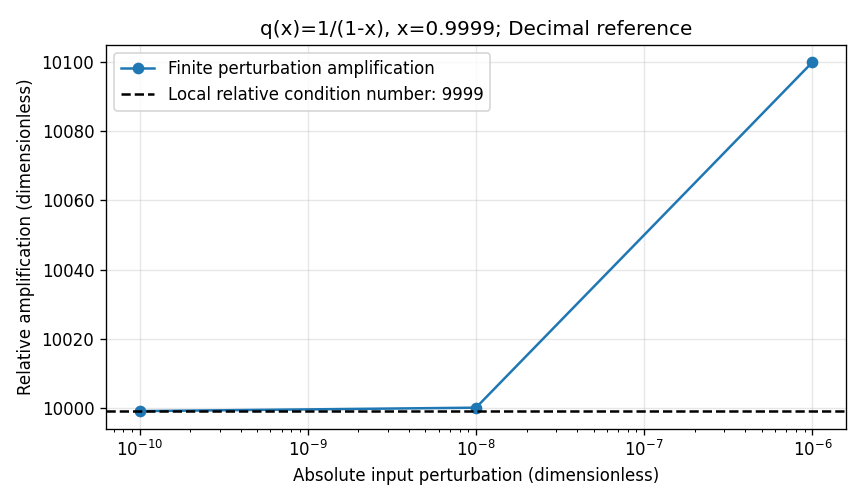

In [9]:
fig,ax=plt.subplots(figsize=(7.2,4.2))
ax.semilogx(t3.dx.astype(float),t3.amplification,'o-',label='Finite perturbation amplification')
ax.axhline(9999,color='black',linestyle='--',label='Local relative condition number: 9999')
ax.set(xlabel='Absolute input perturbation (dimensionless)',ylabel='Relative amplification (dimensionless)',title='q(x)=1/(1-x), x=0.9999; Decimal reference')
ax.grid(True,alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig('图片/A2组-条件数扰动.png',dpi=180); plt.show()
print('g(x)在正输入下的相对条件数：')
for val in [1.,1e8,1e16]:
    print('x=',val,'kappa=',0.5*math.sqrt(val/(val+1)))


### 结果解释与本节结论

在 $x=0.9999$ 处，$q(x)=10000$、$\kappa_q=9999$。定义放大率为 $(|\Delta q|/|q|)/(|\Delta x|/|x|)$，实验得到：

| $\Delta x$ | 输入相对变化 | 输出相对变化 | 实测放大率 |
| --- | --- | --- | --- |
| $10^{-6}$ | 约 $1.0001\times10^{-6}$ | 约0.010101 | 10100 |
| $10^{-8}$ | 约 $1.0001\times10^{-8}$ | 约 $1.0001\times10^{-4}$ | 10000 |
| $10^{-10}$ | 约 $1.0001\times10^{-10}$ | 约 $1.000001\times10^{-6}$ | 9999.009999 |

精确有限扰动关系为 $\Delta q/q=\Delta x/(1-x-\Delta x)$，因此放大率 $x/|1-x-\Delta x|$；它只有在扰动足够小时才接近9999。这里的差异有数学解释，并非Decimal算法突然失稳。若扰动跨过极点1，一阶解释更不能照搬。

同一 $g(x)$ 的算法比较另存为 `A2组-算法误差.csv`。在 $x=10^{16}$ 处，直接式与有理化式的相对误差分别为1与约 $4.59\times10^{-17}$，但 $\kappa_g\approx1/2$。这组证据支持“该直接表达式在此输入上数值不可靠”，不构成对所有输入或所有算法稳定性的完整证明。$x=0$ 仅报告算法误差，不把相对条件数公式硬套到零点。

### 易错点与讨论

病态问题不等于程序写错；更换算法可以减少额外误差，却不能恢复输入中不存在的信息。良态问题也不保证任意实现可靠。若只比较两个相同公式的float64程序，它们可能共同得到错误的0，因此两程序一致不能替代独立参考。

**随堂提问：** 甲实验对 $q$ 改变输入，得到约一万倍的相对放大；乙实验固定 $g(10^{16})$，改变表达式，答案从0变为约 $5\times10^{-9}$。甲对应问题敏感性，乙对应算法行为。两者使用的比较对象不同，不能合并成一句“计算机精度不够”。


## 1.4 AI关联：训练中的数值问题（2学时）

### 概念讲解：从指数到训练损失

分类模型常输出一组实数 $z_i$，称为logits，softmax把它们映射为概率：

$$p_i=\frac{e^{z_i}}{\sum_{j=1}^n e^{z_j}}.$$

公式中的概率位于0与1之间，却不意味着中间指数安全。大正数的指数可能上溢成inf，随后inf/inf变为NaN；全为大负数时，指数可能都下溢为0，随后得到0/0。float32的最大有限数约为 $3.40\times10^{38}$，float64约为 $1.80\times10^{308}$，其自然对数分别约为88.72和709.78。指数输入超过这些范围就有上溢风险。

下溢包括进入非正规数区间，极小值还可能被舍入成0。正阈值与负阈值不对称，不能简单把88.72取负当成float32“所有指数变0”的界。本节让溢出只发生在标注的教学对照代码中。[2]

### 关键推导：稳定softmax、log-sum-exp与损失

设所有logits有限，$m=\max_jz_j$，则

$$p_i=\frac{e^{z_i-m}e^m}{e^m\sum_j e^{z_j-m}}
=\frac{e^{z_i-m}}{\sum_j e^{z_j-m}}.$$

实数中这是恒等变形。新指数的输入不大于0，至少有一项为 $e^0=1$，因此避免了正指数上溢和所有指数同时下溢。很小的概率仍可能下溢为0。它还假设减法的范围可处理：对极端反号、接近dtype边界的logits，$z_i-m$ 自身也可能溢出；本节实验取值不涉及这一极限。输入含NaN、正无穷或全负无穷时也需另定规则，不能套用有限输入结论。[3]

定义log-sum-exp：

$$L(z)=\log\sum_j e^{z_j}=m+\log\sum_j e^{z_j-m}.$$

对于真实类别 $y$，单样本交叉熵为

$$\ell=-\log p_y=(m-z_y)+\log\sum_j e^{z_j-m}.$$

最后的计算次序先求 $m-z_y$，可避免先形成 $m+$ 小增量再减去接近的 $z_y$。这也比“先softmax，再对小概率取log”更可靠：例如 $z=[1000,0,-1000],y=2$（Python从0编号），float64的第三个概率会下溢为0，但对数域损失仍能得到2000。

对有限logits的精确数学表达式求导，有

$$\frac{\partial\ell}{\partial z_i}=p_i-\mathbf1_{i=y}.$$

局部稳定的概率或损失计算能避免一类数值故障，但不保证整个训练过程可靠。即使损失有限、概率和为1，极小概率也可能已变成0。训练还有梯度传播、参数更新尺度及优化器状态等问题。

### 实验设计：预测、输入与判据

| 项目 | 设计 |
| --- | --- |
| logits | $[1000,1001,1002]$、$[-1000,-1001,-1002]$、$[1000,0,-1000]$，两种dtype |
| 预测 | 直接实现出现NaN；减最大值版本有限且和约为1；稀有类的概率可能为0而对数域损失有限 |
| 独立参考 | 80位Decimal.exp构造原始softmax，参考损失由Decimal.ln计算 |
| 指标与容差 | 有限性、概率和、概率最大绝对误差；float32为 $10^{-6}$，float64为 $10^{-14}$ |
| 梯度尺度演示 | $w=1$，更新量 $10^{-8}$，比较两种dtype保存的 $w-10^{-8}$ |
| 环境与预算 | 同1.1，CPU，无训练/随机数/数据划分，约数秒 |

容差是本例的验收阈值，约为少量基本运算下机器精度的若干倍，并非适用于任意类别数或logits范围的定理。



In [10]:
def stable_softmax(z):
    z=np.asarray(z)
    if z.ndim != 1 or not np.isfinite(z).all():
        raise ValueError('finite one-dimensional logits required')
    a=np.exp(z-np.max(z))
    return a/np.sum(a,dtype=z.dtype)
def stable_ce(z,y):
    m=np.max(z)
    return (m-z[y])+np.log(np.sum(np.exp(z-m),dtype=z.dtype))
def decimal_softmax(values):
    with localcontext() as c:
        c.prec=80
        a=[Decimal(str(v)).exp() for v in values]
        total=sum(a)
        return [v/total for v in a]
rows=[]
for values in [[1000,1001,1002],[-1000,-1001,-1002],[1000,0,-1000]]:
    reference=decimal_softmax(values)
    for dt in (np.float32,np.float64):
        z=np.array(values,dtype=dt)
        # Intentional overflow/underflow demonstration, limited to this block.
        with np.errstate(over='ignore',under='ignore',invalid='ignore',divide='ignore'):
            ex=np.exp(z); direct=ex/ex.sum(dtype=dt)
        p=stable_softmax(z)
        with localcontext() as c:
            c.prec=80
            err=max(abs(dfraction(v)-r) for v,r in zip(p,reference))
        tol=1e-6 if dt==np.float32 else 1e-14
        assert np.isfinite(p).all() and abs(float(p.sum())-1)<tol and err<Decimal(str(tol))
        rows.append(dict(logits=str(values),dtype=dt.__name__,direct_exp_has_inf=bool(np.isinf(ex).any()),
                         direct_has_nan=bool(np.isnan(direct).any()),stable_finite=bool(np.isfinite(p).all()),
                         probability_sum=float(p.sum()),stable_probabilities=str(p.tolist()),max_abs_error=float(err),max_abs_error_decimal=str(err),probability_sum_error=abs(float(p.sum())-1),tolerance=tol))
t5=pd.DataFrame(rows); print(t5.to_string(index=False)); t5.to_csv('A2组-softmax.csv',index=False)

# 对“只是共同平移logits”作变形关系核验；此测试不能替代高精度参考。
for dt,tol in [(np.float32,1e-6),(np.float64,1e-14)]:
    base=np.array([0.,1.,2.],dtype=dt)
    assert np.max(np.abs(stable_softmax(base)-stable_softmax(base+dt(1000)))) < tol
print('共同平移不变性检查通过（本例可精确表示平移后的差值）。')


               logits   dtype  direct_exp_has_inf  direct_has_nan  stable_finite  probability_sum                                           stable_probabilities  max_abs_error                                                                  max_abs_error_decimal  probability_sum_error    tolerance
   [1000, 1001, 1002] float32                True            True           True              1.0  [0.09003057330846786, 0.2447284609079361, 0.6652409434318542]   1.234297e-08          1.234296764148214328017474540493276906025056068390570525284864644215184525E-8           0.000000e+00 1.000000e-06
   [1000, 1001, 1002] float64                True            True           True              1.0 [0.09003057317038043, 0.24472847105479767, 0.6652409557748218]   1.045442e-16                 1.0454416673312352427265432667743806068390570525284864644215184525E-16           1.110223e-16 1.000000e-14
[-1000, -1001, -1002] float32               False            True           True              1.0  [0.6

In [11]:
z=np.array([1000.,0.,-1000.],dtype=np.float64); y=2
p=stable_softmax(z)
with np.errstate(divide='ignore'):
    naive_loss=-np.log(p[y])
loss=stable_ce(z,y)
with localcontext() as c:
    c.prec=80
    ref_loss=-decimal_softmax([1000,0,-1000])[y].ln()
print('probabilities:',p,'probability-then-log loss:',naive_loss)
print('log-domain loss:',loss,'Decimal reference:',ref_loss)
assert np.isinf(naive_loss) and np.isfinite(loss) and abs(loss-float(ref_loss))<1e-12
for dt in (np.float32,np.float64):
    w=dt(1); delta=dt('1e-8'); updated=dt(w-delta)
    print(dt.__name__,'updated parameter:',repr(float(updated)), 'change:',float(w-updated))
assert np.float32(np.float32(1)-np.float32('1e-8'))==np.float32(1)



probabilities: [1. 0. 0.] probability-then-log loss: inf
log-domain loss: 2000.0 Decimal reference: 2000.0000000000000000000000000000000000000000000000000000000000000000000000000000
float32 updated parameter: 1.0 change: 0.0
float64 updated parameter: 0.99999999 change: 1.0000000050247593e-08


### 梯度核对：损失的导数是否与概率一致

对中等幅度logits $z=[0.2,-0.4,0.7]$、类别1，从解析式得到梯度 $p-\mathrm{onehot}(y)$。用中心差分 $(\ell(z+he_i)-\ell(z-he_i))/(2h)$、$h=10^{-5}$ 作局部数值核验。验收为最大绝对差小于 $10^{-8}$；步长过小仍会有本章1.2讨论的舍入风险。这不是网络训练实验。

 component  analytic  central_difference  abs_difference
         0  0.312741            0.312741    1.270872e-12
         1 -0.828364           -0.828364    3.011813e-12
         2  0.515623            0.515623    4.282685e-12
有限输入约定下已拒绝： [nan, 0.0]
有限输入约定下已拒绝： [inf, 0.0]
有限输入约定下已拒绝： [-inf, -inf]


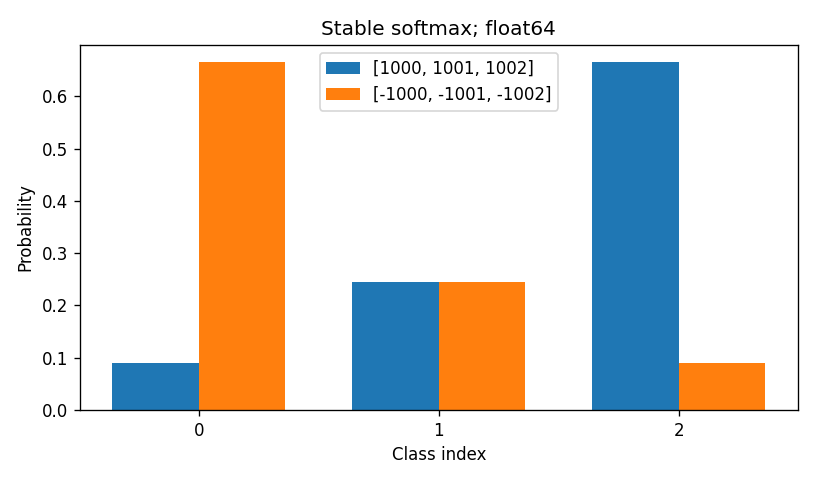

In [12]:
z_check=np.array([0.2,-0.4,0.7],dtype=np.float64)
y_check=1; step=1e-5
analytic=stable_softmax(z_check).copy(); analytic[y_check]-=1
numerical=[]
for i in range(len(z_check)):
    plus=z_check.copy(); minus=z_check.copy()
    plus[i]+=step; minus[i]-=step
    numerical.append((stable_ce(plus,y_check)-stable_ce(minus,y_check))/(2*step))
gradient_table=pd.DataFrame(dict(component=np.arange(3),analytic=analytic,central_difference=numerical,
    abs_difference=np.abs(analytic-np.array(numerical))))
print(gradient_table.to_string(index=False))
assert gradient_table.abs_difference.max() < 1e-8
assert abs(analytic.sum()) < 1e-14
gradient_table.to_csv('A2组-损失梯度.csv',index=False)
for bad in [[float('nan'),0.],[float('inf'),0.],[-float('inf'),-float('inf')]]:
    try: stable_softmax(np.array(bad))
    except ValueError: print('有限输入约定下已拒绝：',bad)
    else: raise AssertionError('非有限logits未被拒绝')
fig,ax=plt.subplots(figsize=(6.8,4))
for values,offset,label in [([1000,1001,1002],-.18,'[1000, 1001, 1002]'),([-1000,-1001,-1002],.18,'[-1000, -1001, -1002]')]:
    ax.bar(np.arange(3)+offset,stable_softmax(np.array(values,dtype=np.float64)),width=.36,label=label)
ax.set(xticks=[0,1,2],xlabel='Class index',ylabel='Probability',title='Stable softmax; float64')
ax.legend(); fig.tight_layout(); fig.savefig('图片/A2组-softmax概率.png',dpi=180); plt.show()


### 结果解释与本节结论

直接softmax在三组输入、两种dtype下都产生非有限结果：大正数组有指数inf，全负数组的分母为0。减最大值后的结果均有限，概率和在上述容差内等于1。第一组float64的概率约为 $[0.09003057,0.24472847,0.66524096]$；第二组相反次序。第三组在float64下得到 $[1,0,0]$，尽管实数中的后两项严格为正。

以第三组的类别2为真类，先取概率再求 $-\log p_y$ 得到inf，对数域损失得到有限的2000，接近Decimal参考。注意：这说明该局部损失计算成功，没有证明模型预测准确，也没有运行真实网络训练。

微小更新实验中，float32的 $1-10^{-8}$ 保存为1，而float64保存为0.99999999。一个更新可能小于参数所在尺度上的分辨率。损失缩放可在某些混合精度计算中帮助梯度避免下溢，但不能把最终仍存为低精度的参数凭空变得更细；更高精度的主参数和累积可解决不同环节的问题。本章只作尺度辨析，不将其当作完整混合精度训练教程。

### 易错点与讨论

“没有NaN”是必要检查之一，不能作为正确性的充分证据；第三组概率已经揭示这一点。“loss下降”还涉及任务、实现、优化与评价，不能据此证明数值计算准确。AI生成的公式也须检查中间量，不能只看最终数学值的取值范围。

**随堂提问：** 教学构造的建议是“概率不超过1，直接计算指数不会上溢”。它错在哪里？界限约束的是最终比值，不是分子和分母。用 $[1000,1001,1002]$ 运行两种实现，即可给出反例；这是一道构造辨析题，不是虚构的真实AI发言记录。


## 全章实验汇总与复现记录

以下汇总由实际变量生成，不手工填写“通过”。检查范围限于指定输入；课程核心依赖匹配不代表操作系统、所有库及Jupyter交互流程完全相同。生成文件与本Notebook位于同一工作目录。


In [13]:
best=t2.loc[t2.total_error.idxmin()]
summary={
 'course_core_dependencies_match':bool(versions['course_environment_match']),
 'rationalization_relative_error_at_1e16':str(e_stable),
 'forward_difference_best_scanned_h':float(best.h),
 'forward_difference_best_scanned_abs_error':float(best.total_error),
 'forward_difference_at_1e_minus16':float(t2.iloc[-1].approximation),
 'perturbation_amplifications':t3.amplification.tolist(),
 'stable_softmax_all_cases_finite':bool(t5.stable_finite.all()),
 'stable_softmax_max_normalization_error':float(t5.probability_sum_error.max()),
 'rare_class_log_domain_loss':float(loss),
 'gradient_check_max_abs_error':float(gradient_table.abs_difference.max()),
 'precision_reference_crosscheck_passed':True,
 'student_manual_review':'not yet recorded',
 'B_C_independent_review':'not yet performed',
 'jupyter_kernel_restart_run_all':'not executed on restricted host; fresh Python sequential execution used'
}
print(json.dumps(summary,ensure_ascii=False,indent=2))
Path('A2组-实验汇总.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('实验完成：请核对正文、图表及以上结论后保存Notebook。')


{
  "course_core_dependencies_match": true,
  "rationalization_relative_error_at_1e16": "4.5922560830128472573390654842499671161196757352099962491665234464829906940593742E-17",
  "forward_difference_best_scanned_h": 1e-08,
  "forward_difference_best_scanned_abs_error": 6.602750935127739e-09,
  "forward_difference_at_1e_minus16": 0.0,
  "perturbation_amplifications": [
    10100.0,
    10000.0,
    9999.009999009999
  ],
  "stable_softmax_all_cases_finite": true,
  "stable_softmax_max_normalization_error": 5.960464477539063e-08,
  "rare_class_log_domain_loss": 2000.0,
  "gradient_check_max_abs_error": 4.282685317491541e-12,
  "precision_reference_crosscheck_passed": true,
  "student_manual_review": "not yet recorded",
  "B_C_independent_review": "not yet performed",
  "jupyter_kernel_restart_run_all": "not executed on restricted host; fresh Python sequential execution used"
}
实验完成：请核对正文、图表及以上结论后保存Notebook。


## 回到开场：用证据回答

开场两种算法确实不一致：在本次float64实验中，直接式为0，有理化式为 $5\times10^{-9}$。第1.1节解释了 $10^{16}+1$ 为什么可能仍存成 $10^{16}$；第1.2节通过80位参考检验了改写后的精度；第1.3节进一步表明此函数在大 $x$ 处的相对条件数约为 $1/2$，所以应先检查表达式，而不能把失败简单归为问题病态。

面对屏幕上的3.141592653589793，位数本身不提供可信度。需要说清数学目标、输入误差、运算格式、算法误差和独立参考；若无法给出严格界，就明确说明实验证据覆盖的范围。一次正确输出只能支持这次输入上的结论。

## 本章小结与课后习题

**浮点数**解释实数如何被有限表示。机器间隔随尺度变化，单位舍入误差不等于整段程序误差；真值为零时相对误差不定义。

**条件数**量化问题的局部敏感性。标量相对条件数 $|xf'(x)/f(x)|$ 要求可微且分母、输入非零；较大的条件数提示输入信息的不足可能显著影响答案。

**稳定性**关注计算过程怎样放大误差。同一问题可以有数值表现不同的等价表达式。有理化、选择差分步长及减最大值，分别处理不同环节，不能互相替代，也不构成对整个模型的正确性证明。

[四道课后习题](A2组-习题.md)与四节对应；[参考解答](A2组-习题参考解答.md)单独保存。实验保存在[A2组-实验.ipynb](A2组-实验.ipynb)。

## 选读边界

本章不展开矩阵后向误差理论、完整网络训练与混合精度工程。后向误差、残差和矩阵条件数留待第4章；本章仅建立分辨问题敏感性与算法可靠性的基础。

## 参考资料、图片来源与AI使用

公式的主要推导已在正文展开，不以未查阅的教材页码充当出处。下列外部资料给出进一步核对入口；学生须在提交前亲自打开原文核对，不能把助手的推导或运行视为学生人工核验。

| 编号 | 支撑内容 | 资料与位置 | 核对状态 |
| --- | --- | --- | --- |
| [1] | 小数表示、0.1及显示限制 | Python 3.12官方教程，第15章 [Floating-Point Arithmetic](https://docs.python.org/3.12/tutorial/floatingpoint.html) | 提供官方原文入口；学生尚未核对 |
| [2] | eps、正规/非正规范围、finfo定义 | NumPy 2.3官方文档 [numpy.finfo](https://numpy.org/doc/2.3/reference/generated/numpy.finfo.html) | 属性由实验读取；学生原文核对尚未完成 |
| [3] | 减最大值softmax、稳定性限制 | SciPy官方文档 [scipy.special.softmax](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.softmax.html)，Notes及其参考文献 | 正文独立推导并运行；学生原文核对尚未完成 |
| [4] | 差分、条件数、有理化、交叉熵 | 本稿1.2—1.4节的Taylor展开、求导与代数推导 | AI辅助推导；学生须逐步复核 |
| 图01-1 | 开场概念图 | 课程仓库 `模板/图片/A-章节导入.svg`，沿用原图 | 来源为模板初始化助手；未声称本组原创 |
| 图01-2 | 步长误差曲线 | 本组Notebook 1.2代码生成 | 助手实际运行，学生及B/C待复现 |

本次AI辅助过程及采纳范围见[A2组-AI对话记录.md](A2组-AI对话记录.md)，环境、局限与交付情况见[A2组-编写报告.md](A2组-编写报告.md)。
